Implementación del grafo no dirigido y ponderado

In [1]:
import numpy as np

class Graph:
    def __init__(self):
        self.nodes = {}
        self.edges = {}

    def add_node(self, node_id, name):
        if node_id not in self.nodes:
            self.nodes[node_id] = name
            self.edges[node_id] = {}

    def add_edge(self, a, b):
        if a not in self.nodes or b not in self.nodes:
            raise ValueError("Ambos nodos deben existir")

        if a == b:
            return

        self.edges[a][b] = self.edges[a].get(b, 0) + 1
        self.edges[b][a] = self.edges[b].get(a, 0) + 1

    def total_nodes(self):
        return len(self.nodes)

    def total_edges(self):
        return sum(len(v) for v in self.edges.values()) // 2

    def max_degree_nodes(self):
        if not self.nodes:
            return {}

        degrees = {
            node_id: len(neighbors)
            for node_id, neighbors in self.edges.items()
        }

        max_degree = max(degrees.values())

        return {
            node_id: {
                "name": self.nodes[node_id],
                "degree": degree
            }
            for node_id, degree in degrees.items()
            if degree == max_degree
        }

    def adjacency(self):
        ids = list(self.nodes.keys())
        indices = {node_id: i for i, node_id in enumerate(ids)}
        A = np.zeros((len(ids), len(ids)), dtype=int)

        for a, neighbors in self.edges.items():
            for b, weight in neighbors.items():
                A[indices[a], indices[b]] = weight

        return A, ids

Prueba de funcionamiento de la clase Graph

In [2]:
grafo_prueba = Graph()

grafo_prueba.add_node(1, "Elijah Wood")
grafo_prueba.add_node(2, "Actor A")
grafo_prueba.add_node(3, "Actor B")

grafo_prueba.add_edge(1, 2)
grafo_prueba.add_edge(1, 2)
grafo_prueba.add_edge(1, 2)
grafo_prueba.add_edge(1, 3)

A, ids = grafo_prueba.adjacency()

print("Total de nodos:", grafo_prueba.total_nodes())
print("Total de aristas:", grafo_prueba.total_edges())
print("Nodos de mayor grado:", grafo_prueba.max_degree_nodes())
print("Orden de los IDs:", ids)
print("Matriz de adyacencia:")
print(A)

Total de nodos: 3
Total de aristas: 2
Nodos de mayor grado: {1: {'name': 'Elijah Wood', 'degree': 2}}
Orden de los IDs: [1, 2, 3]
Matriz de adyacencia:
[[0 3 1]
 [3 0 0]
 [1 0 0]]


Verificar la configuración de TMDB

In [3]:
import os
from dotenv import load_dotenv

load_dotenv(".env")

API_KEY = None

if API_KEY:
    print("API key de TMDB disponible.")
else:
    print("Sin API key. Se utilizarán los datos almacenados en caché.")

Sin API key. Se utilizarán los datos almacenados en caché.


Conexión con TMDB y caché JSON

In [4]:

import json
import requests
from pathlib import Path

class TMDBAPIUtils:
    def __init__(self, api_key=None, cache_dir="cache"):
        self.api_key = api_key
        self.base_url = "https://api.themoviedb.org/3"
        self.cache_dir = Path(cache_dir)
        self.cache_dir.mkdir(parents=True, exist_ok=True)

    def get_data(self, endpoint):
        nombre_archivo = endpoint.strip("/").replace("/", "_")
        ruta_cache = self.cache_dir / f"{nombre_archivo}.json"

        if ruta_cache.exists():
            with open(ruta_cache, "r", encoding="utf-8") as archivo:
                return json.load(archivo)

        if not self.api_key:
            raise ValueError(
                f"No hay API key ni caché para {endpoint}"
            )

        url = f"{self.base_url}/{endpoint.lstrip('/')}"

        respuesta = requests.get(
            url,
            params={"api_key": self.api_key},
            timeout=30
        )

        respuesta.raise_for_status()
        datos = respuesta.json()

        with open(ruta_cache, "w", encoding="utf-8") as archivo:
            json.dump(datos, archivo, ensure_ascii=False, indent=4)

        return datos

    def get_movie_cast(self, movie_id, limit=5, exclude_ids=None):
        if exclude_ids is None:
            exclude_ids = []

        datos = self.get_data(f"movie/{movie_id}/credits")

        elenco = [
            {
                "id": actor["id"],
                "name": actor["name"],
                "order": actor["order"]
            }
            for actor in datos.get("cast", [])
            if 0 <= actor["order"] < limit
            and actor["id"] not in exclude_ids
        ]

        return sorted(elenco, key=lambda actor: actor["order"])

    def get_movie_credits_for_person(self, person_id, start_date, end_date):
        datos = self.get_data(f"person/{person_id}/movie_credits")
        peliculas = []

        for pelicula in datos.get("cast", []):
            fecha = pelicula.get("release_date", "")
            generos = pelicula.get("genre_ids", [])
            personaje = pelicula.get("character", "").strip().lower()

            if not fecha or not (start_date <= fecha <= end_date):
                continue

            if 99 in generos:
                continue

            if personaje in ["self", "himself", "herself", "themselves"]:
                continue

            peliculas.append({
                "id": pelicula["id"],
                "title": pelicula["title"],
                "release_date": fecha,
                "order": pelicula.get("order")
            })

        return sorted(
            peliculas,
            key=lambda pelicula: pelicula["release_date"]
        )


Consulta de información del actor

In [5]:
tmdb = TMDBAPIUtils(api_key=API_KEY)

datos_actor = tmdb.get_data("person/109")

print("Nombre:", datos_actor["name"])
print("ID:", datos_actor["id"])
print("Profesión:", datos_actor.get("known_for_department"))
print("Lugar de nacimiento:", datos_actor.get("place_of_birth"))

Nombre: Elijah Wood
ID: 109
Profesión: Acting
Lugar de nacimiento: Cedar Rapids, Iowa, USA


Prueba de consulta de los cinco primeros actores

In [6]:
elenco = tmdb.get_movie_cast(
    movie_id=120,
    limit=5,
    exclude_ids=[]
)

print("Primeros cinco actores del elenco:")

for actor in elenco:
    print(
        f"Orden: {actor['order']} | "
        f"ID: {actor['id']} | "
        f"Nombre: {actor['name']}"
    )

Primeros cinco actores del elenco:
Orden: 0 | ID: 109 | Nombre: Elijah Wood
Orden: 1 | ID: 1327 | Nombre: Ian McKellen
Orden: 2 | ID: 110 | Nombre: Viggo Mortensen
Orden: 3 | ID: 1328 | Nombre: Sean Astin
Orden: 4 | ID: 65 | Nombre: Ian Holm


Consultar las películas de Elijah Wood

In [7]:
peliculas_elijah = tmdb.get_movie_credits_for_person(
    person_id=109,
    start_date="1975-01-01",
    end_date="2025-12-31"
)

print("Total de películas filtradas:", len(peliculas_elijah))
print("\nPrimeras 10 películas:")

for pelicula in peliculas_elijah[:10]:
    print(
        f"{pelicula['release_date']} | "
        f"{pelicula['title']} | "
        f"Orden: {pelicula['order']}"
    )

Total de películas filtradas: 71

Primeras 10 películas:
1989-11-22 | Back to the Future Part II | Orden: 17
1990-01-12 | Internal Affairs | Orden: 30
1990-05-01 | Child in the Night | Orden: 6
1990-10-05 | Avalon | Orden: 9
1991-09-18 | Paradise | Orden: 2
1992-01-01 | The Witness | Orden: 1
1992-02-21 | Radio Flyer | Orden: 3
1992-05-03 | Day-O | Orden: 1
1992-12-16 | Forever Young | Orden: 2
1993-04-02 | The Adventures of Huck Finn | Orden: 0


Filtrado de películas según posición en el elenco

In [8]:
peliculas_validas = [
    pelicula
    for pelicula in peliculas_elijah
    if pelicula["order"] is not None
    and 0 <= pelicula["order"] < 5
]

print("Películas filtradas inicialmente:", len(peliculas_elijah))
print("Películas con Elijah Wood entre los primeros 5:", len(peliculas_validas))

print("\nPrimeras 10 películas válidas:")

for pelicula in peliculas_validas[:10]:
    print(
        f"{pelicula['release_date']} | "
        f"{pelicula['title']} | "
        f"Orden: {pelicula['order']}"
    )

Películas filtradas inicialmente: 71
Películas con Elijah Wood entre los primeros 5: 51

Primeras 10 películas válidas:
1991-09-18 | Paradise | Orden: 2
1992-01-01 | The Witness | Orden: 1
1992-02-21 | Radio Flyer | Orden: 3
1992-05-03 | Day-O | Orden: 1
1992-12-16 | Forever Young | Orden: 2
1993-04-02 | The Adventures of Huck Finn | Orden: 0
1993-09-24 | The Good Son | Orden: 1
1994-07-22 | North | Orden: 0
1994-11-04 | The War | Orden: 0
1996-05-17 | Flipper | Orden: 0


Agregar a Elijah Wood y sus compañeros de reparto

In [9]:
grafo = Graph()

ID_SEMILLA = 109
grafo.add_node(ID_SEMILLA, "Elijah Wood")

peliculas_semilla = {}
errores = []

for pelicula in peliculas_validas:
    movie_id = pelicula["id"]

    try:
        elenco = tmdb.get_movie_cast(
            movie_id=movie_id,
            limit=5,
            exclude_ids=[]
        )

        ids_elenco = {actor["id"] for actor in elenco}

        if ID_SEMILLA not in ids_elenco:
            continue

        peliculas_semilla[movie_id] = {
            "title": pelicula["title"],
            "cast": elenco
        }

        for actor in elenco:
            grafo.add_node(actor["id"], actor["name"])

    except requests.RequestException as error:
        errores.append((movie_id, str(error)))

print("Películas válidas consultadas:", len(peliculas_semilla))
print("Actores únicos encontrados:", grafo.total_nodes())
print("Consultas fallidas:", len(errores))

Películas válidas consultadas: 51
Actores únicos encontrados: 179
Consultas fallidas: 0


Consulta de filmografías de los actores del grafo

In [10]:
from collections import defaultdict

creditos_actores = {}
actores_por_pelicula = defaultdict(set)
titulos_peliculas = {}

for indice, actor_id in enumerate(grafo.nodes, start=1):
    peliculas = tmdb.get_movie_credits_for_person(
        person_id=actor_id,
        start_date="1975-01-01",
        end_date="2025-12-31"
    )

    creditos_actores[actor_id] = peliculas

    for pelicula in peliculas:
        orden = pelicula["order"]

        if orden is not None and 0 <= orden < 5:
            movie_id = pelicula["id"]

            actores_por_pelicula[movie_id].add(actor_id)
            titulos_peliculas[movie_id] = pelicula["title"]

    if indice % 25 == 0:
        print(f"Procesados {indice} de {grafo.total_nodes()} actores")

print("\nActores procesados:", len(creditos_actores))
print("Películas distintas encontradas:", len(actores_por_pelicula))

Procesados 25 de 179 actores
Procesados 50 de 179 actores
Procesados 75 de 179 actores
Procesados 100 de 179 actores
Procesados 125 de 179 actores
Procesados 150 de 179 actores
Procesados 175 de 179 actores

Actores procesados: 179
Películas distintas encontradas: 5372


Construcción de aristas ponderadas entre actores

In [11]:
from itertools import combinations
from collections import defaultdict

# REINICIAR LAS ARISTAS SIN ELIMINAR LOS NODOS
grafo.edges = {
    actor_id: {}
    for actor_id in grafo.nodes
}

# IDENTIFICAR PELICULAS COMPARTIDAS
peliculas_por_pareja = defaultdict(set)

for movie_id, actores in actores_por_pelicula.items():
    actores_ordenados = sorted(actores)

    for actor_a, actor_b in combinations(actores_ordenados, 2):
        pareja = (actor_a, actor_b)
        peliculas_por_pareja[pareja].add(movie_id)

# CONSTRUIR LAS ARISTAS
for (actor_a, actor_b), peliculas in peliculas_por_pareja.items():
    for movie_id in peliculas:
        grafo.add_edge(actor_a, actor_b)

# MOSTRAR RESULTADOS
print("Total de nodos:", grafo.total_nodes())
print("Total de aristas:", grafo.total_edges())

print("\nActor(es) de mayor grado:")

for actor_id, info in grafo.max_degree_nodes().items():
    print(
        f"{info['name']} | "
        f"ID: {actor_id} | "
        f"Grado: {info['degree']}"
    )

print("\nTotal de colaboraciones ponderadas:",
      sum(len(peliculas) for peliculas in peliculas_por_pareja.values()))

Total de nodos: 179
Total de aristas: 781

Actor(es) de mayor grado:
Elijah Wood | ID: 109 | Grado: 178

Total de colaboraciones ponderadas: 866


Visualización de la red de colaboración de Elijah Wood

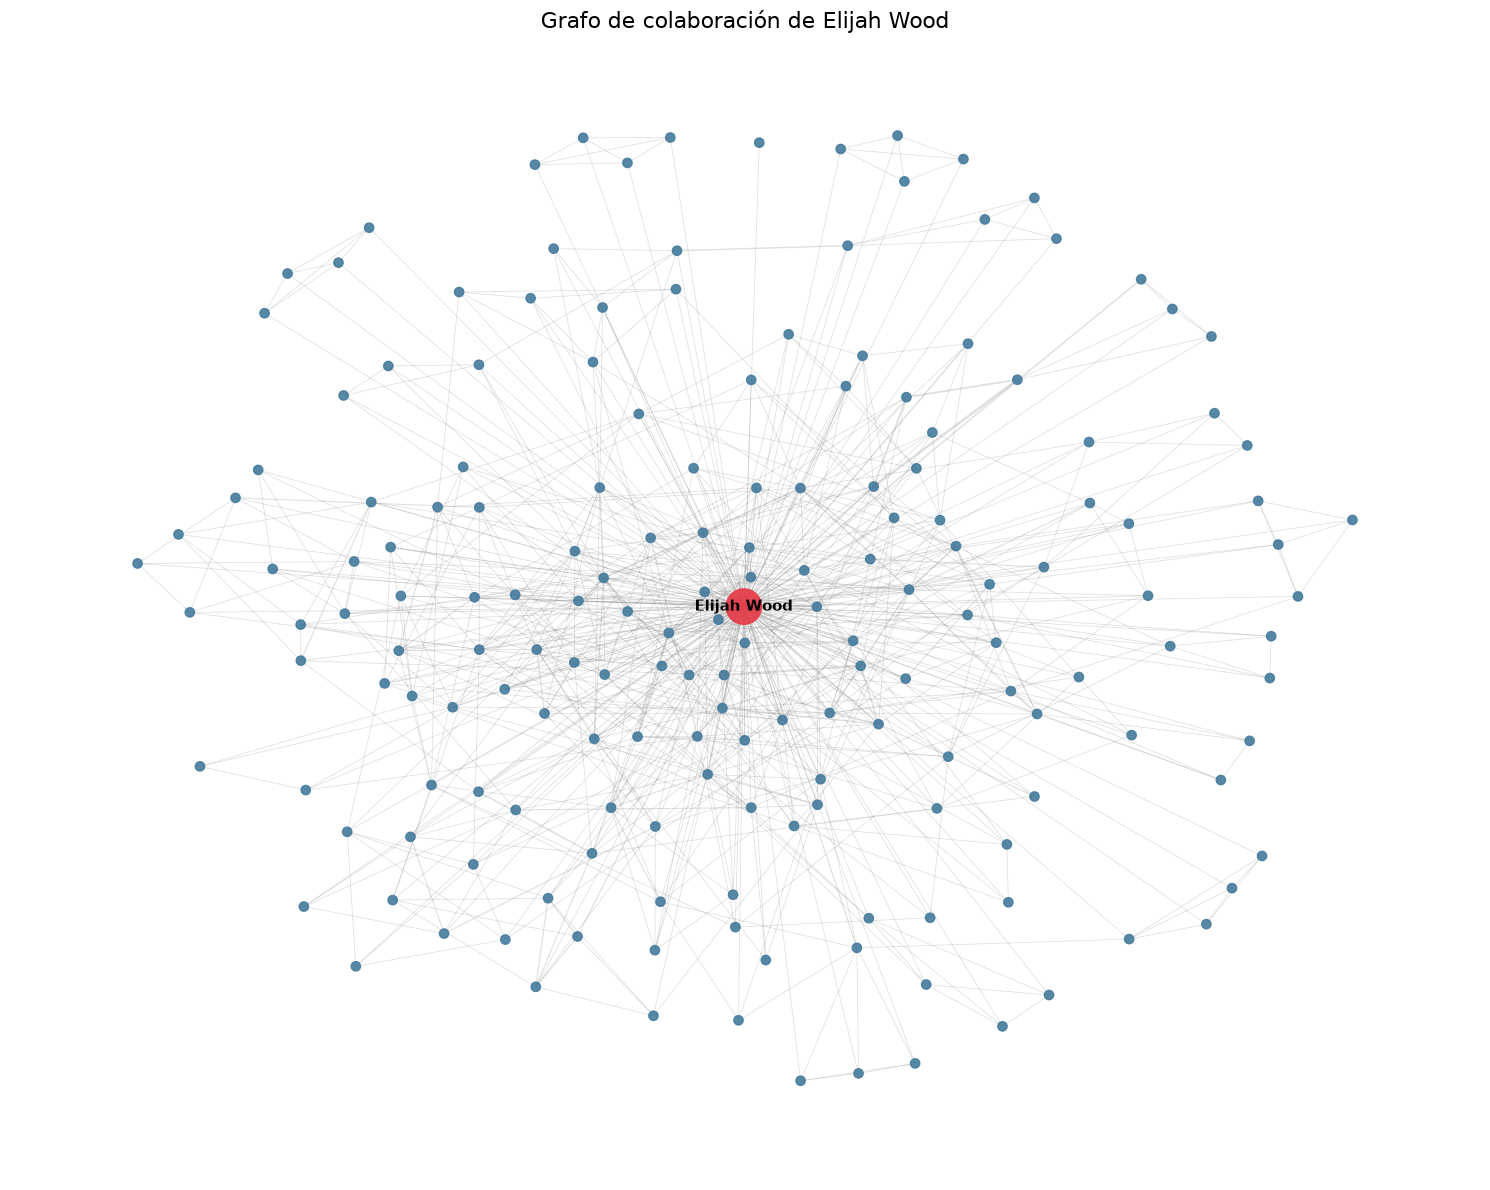

In [12]:
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path

# CREAR GRAFO PARA VISUALIZACION
G = nx.Graph()

for actor_id, nombre in grafo.nodes.items():
    G.add_node(actor_id, name=nombre)

for actor_a, vecinos in grafo.edges.items():
    for actor_b, peso in vecinos.items():
        if actor_a < actor_b:
            G.add_edge(actor_a, actor_b, weight=peso)

# CALCULAR POSICIONES
posiciones = nx.spring_layout(
    G,
    seed=42,
    weight="weight",
    iterations=150
)

# DIFERENCIAR AL ACTOR PRINCIPAL
colores = [
    "#E63946" if nodo == 109 else "#457B9D"
    for nodo in G.nodes()
]

tamanios = [
    650 if nodo == 109 else 45
    for nodo in G.nodes()
]

pesos = nx.get_edge_attributes(G, "weight")

anchos = [
    0.3 + 0.25 * pesos[arista]
    for arista in G.edges()
]

# DIBUJAR
plt.figure(figsize=(15, 12))

nx.draw_networkx_edges(
    G,
    posiciones,
    width=anchos,
    alpha=0.25,
    edge_color="gray"
)

nx.draw_networkx_nodes(
    G,
    posiciones,
    node_color=colores,
    node_size=tamanios,
    alpha=0.9
)

nx.draw_networkx_labels(
    G,
    posiciones,
    labels={109: "Elijah Wood"},
    font_size=11,
    font_weight="bold"
)

plt.title(
    "Grafo de colaboración de Elijah Wood",
    fontsize=16
)

plt.axis("off")
plt.tight_layout()

# GUARDAR FIGURA
Path("figuras").mkdir(exist_ok=True)

plt.savefig(
    "figuras/grafo_elijah_wood.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Construcción de los Laplacianos del grafo

In [13]:
import numpy as np

# MATRIZ DE ADYACENCIA
A, ids = grafo.adjacency()
A = A.astype(float)

# GRADOS PONDERADOS
grados = np.sum(A, axis=1)

# MATRIZ DIAGONAL
D = np.diag(grados)

# LAPLACIANO NO NORMALIZADO
L = D - A

# LAPLACIANO NORMALIZADO
inversos = np.zeros_like(grados)

mascara = grados > 0
inversos[mascara] = 1 / np.sqrt(grados[mascara])

D_inv_sqrt = np.diag(inversos)

L_sym = np.eye(len(ids)) - D_inv_sqrt @ A @ D_inv_sqrt

# NODOS AISLADOS: DIAGONAL CERO
L_sym[~mascara, ~mascara] = 0

# VERIFICACIONES
print("Dimensiones de A:", A.shape)
print("Dimensiones de L:", L.shape)
print("Dimensiones de L_sym:", L_sym.shape)

print("\n¿A es simétrica?", np.allclose(A, A.T))
print("¿L es simétrica?", np.allclose(L, L.T))
print("¿L_sym es simétrica?", np.allclose(L_sym, L_sym.T))

indice_elijah = ids.index(109)

print("\nGrado simple de Elijah Wood:",
      len(grafo.edges[109]))

print("Grado ponderado de Elijah Wood:",
      grados[indice_elijah])

Dimensiones de A: (179, 179)
Dimensiones de L: (179, 179)
Dimensiones de L_sym: (179, 179)

¿A es simétrica? True
¿L es simétrica? True
¿L_sym es simétrica? True

Grado simple de Elijah Wood: 178
Grado ponderado de Elijah Wood: 188.0


Identificación de componentes conexas mediante BFS

In [14]:
from collections import deque

def componentes_bfs(matriz):
    n = matriz.shape[0]
    visitados = set()
    componentes = []

    for inicio in range(n):
        if inicio in visitados:
            continue

        cola = deque([inicio])
        visitados.add(inicio)
        componente = []

        while cola:
            actual = cola.popleft()
            componente.append(actual)

            vecinos = np.where(matriz[actual] > 0)[0]

            for vecino in vecinos:
                vecino = int(vecino)

                if vecino not in visitados:
                    visitados.add(vecino)
                    cola.append(vecino)

        componentes.append(componente)

    return componentes

# COMPONENTES CON ELIJAH WOOD
componentes_con = componentes_bfs(A)

# MATRIZ SIN ELIJAH WOOD
indice_elijah = ids.index(109)

A_sin = np.delete(
    np.delete(A, indice_elijah, axis=0),
    indice_elijah,
    axis=1
)

ids_sin = [actor_id for actor_id in ids if actor_id != 109]

# COMPONENTES SIN ELIJAH WOOD
componentes_sin = componentes_bfs(A_sin)

print("Componentes con Elijah Wood:", len(componentes_con))
print("Componentes sin Elijah Wood:", len(componentes_sin))

print("\nTamaños de las componentes sin Elijah Wood:")

tamanios = sorted(
    [len(componente) for componente in componentes_sin],
    reverse=True
)

print(tamanios)

Componentes con Elijah Wood: 1
Componentes sin Elijah Wood: 5

Tamaños de las componentes sin Elijah Wood:
[165, 4, 4, 4, 1]


Verificación espectral de componentes conexas

In [15]:
def laplaciano_normalizado(matriz):
    grados = np.sum(matriz, axis=1)

    inversos = np.zeros_like(grados, dtype=float)
    mascara = grados > 0

    inversos[mascara] = 1 / np.sqrt(grados[mascara])

    D_inv = np.diag(inversos)

    L_normalizado = (
        np.eye(len(grados))
        - D_inv @ matriz @ D_inv
    )

    # NODOS AISLADOS
    L_normalizado[~mascara, ~mascara] = 0

    return L_normalizado

# LAPLACIANOS NORMALIZADOS
L_sym_con = laplaciano_normalizado(A)
L_sym_sin = laplaciano_normalizado(A_sin)

# VALORES Y VECTORES PROPIOS
valores_con, vectores_con = np.linalg.eigh(L_sym_con)
valores_sin, vectores_sin = np.linalg.eigh(L_sym_sin)

# CONTAR VALORES PROPIOS CERCANOS A CERO
tolerancia = 1e-8

componentes_espectrales_con = np.sum(
    valores_con < tolerancia
)

componentes_espectrales_sin = np.sum(
    valores_sin < tolerancia
)

print("CON ELIJAH WOOD")
print("Componentes BFS:", len(componentes_con))
print("Componentes espectrales:", componentes_espectrales_con)

print("\nSIN ELIJAH WOOD")
print("Componentes BFS:", len(componentes_sin))
print("Componentes espectrales:", componentes_espectrales_sin)

print("\nPrimeros 8 valores propios sin Elijah Wood:")
print(np.round(valores_sin[:8], 10))

CON ELIJAH WOOD
Componentes BFS: 1
Componentes espectrales: 1

SIN ELIJAH WOOD
Componentes BFS: 5
Componentes espectrales: 5

Primeros 8 valores propios sin Elijah Wood:
[-0.         -0.         -0.          0.          0.          0.04143078
  0.10212792  0.13468655]


### Interpretación de las componentes conexas

El grafo completo presenta una sola componente conexa formada por 179 actores, debido a que Elijah Wood mantiene conexiones directas con los otros 178 nodos. Al eliminarlo, la red se divide en cinco componentes de tamaños 165, 4, 4, 4 y 1, lo que evidencia su importancia para mantener conectados algunos grupos de actores.

Los resultados obtenidos mediante BFS coinciden con el análisis espectral del Laplaciano normalizado. En el grafo completo se identifica un valor propio cercano a cero, mientras que al eliminar a Elijah Wood aparecen cinco valores propios cercanos a cero, correspondientes a las cinco componentes conexas. Esto confirma la consistencia entre ambos métodos.

Cálculo de conectividad algebraica y brechas espectrales

In [16]:
# CONECTIVIDAD ALGEBRAICA
lambda2_con = valores_con[1]
lambda2_sin = valores_sin[1]

print("Conectividad algebraica:")
print(f"Con Elijah Wood: {lambda2_con:.8f}")
print(f"Sin Elijah Wood: {lambda2_sin:.8f}")

# BRECHAS ENTRE VALORES PROPIOS CONSECUTIVOS
brechas_con = np.diff(valores_con)
brechas_sin = np.diff(valores_sin)

# MAYOR BRECHA EN TODO EL ESPECTRO
k_con = int(np.argmax(brechas_con) + 1)
k_sin = int(np.argmax(brechas_sin) + 1)

print("\nMayor brecha espectral con Elijah Wood:")
print("Posición k:", k_con)
print(f"Brecha: {brechas_con[k_con - 1]:.8f}")

print("\nMayor brecha espectral sin Elijah Wood:")
print("Posición k:", k_sin)
print(f"Brecha: {brechas_sin[k_sin - 1]:.8f}")

print("\nNúmero de comunidades propuesto:", k_con)

Conectividad algebraica:
Con Elijah Wood: 0.23442671
Sin Elijah Wood: -0.00000000

Mayor brecha espectral con Elijah Wood:
Posición k: 1
Brecha: 0.23442671

Mayor brecha espectral sin Elijah Wood:
Posición k: 6
Brecha: 0.06069714

Número de comunidades propuesto: 1


Visualización de los primeros 15 valores propios del Laplaciano normalizado

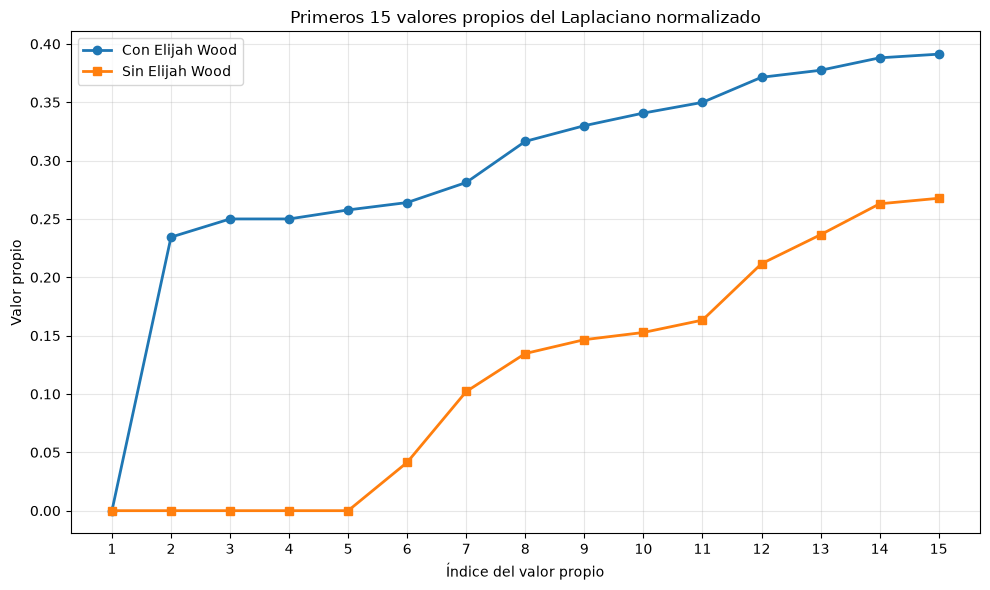

In [17]:
import matplotlib.pyplot as plt

cantidad = 15
indices = np.arange(1, cantidad + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    indices,
    valores_con[:cantidad],
    marker="o",
    linewidth=2,
    label="Con Elijah Wood"
)

plt.plot(
    indices,
    valores_sin[:cantidad],
    marker="s",
    linewidth=2,
    label="Sin Elijah Wood"
)

plt.xlabel("Índice del valor propio")
plt.ylabel("Valor propio")
plt.title("Primeros 15 valores propios del Laplaciano normalizado")

plt.xticks(indices)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "figuras/espectro_laplaciano.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Identificación de comunidades internas mediante brechas espectrales

In [18]:
# BRECHAS ESPECTRALES CON ELIJAH WOOD
brechas_internas = brechas_con.copy()

# EXCLUIR LA PRIMERA BRECHA
brechas_internas[0] = -np.inf

# IDENTIFICAR LAS 10 MAYORES BRECHAS RESTANTES
posiciones = np.argsort(brechas_internas)[::-1][:10]

print("Mayores brechas espectrales después de k=1:\n")

for posicion in posiciones:
    k = posicion + 1

    print(
        f"k = {k:3d} | "
        f"λ{k} = {valores_con[posicion]:.6f} | "
        f"λ{k+1} = {valores_con[posicion + 1]:.6f} | "
        f"Brecha = {brechas_con[posicion]:.6f}"
    )

# MAYOR BRECHA EXCLUYENDO k=1
k_exploratorio = int(posiciones[0] + 1)

print("\nNúmero exploratorio de comunidades:", k_exploratorio)

Mayores brechas espectrales después de k=1:

k =   7 | λ7 = 0.281250 | λ8 = 0.316477 | Brecha = 0.035227
k =  43 | λ43 = 0.719623 | λ44 = 0.747860 | Brecha = 0.028237
k =  42 | λ42 = 0.695468 | λ43 = 0.719623 | Brecha = 0.024155
k =  21 | λ21 = 0.448265 | λ22 = 0.471753 | Brecha = 0.023488
k =  11 | λ11 = 0.349901 | λ12 = 0.371402 | Brecha = 0.021501
k =  46 | λ46 = 0.774462 | λ47 = 0.795185 | Brecha = 0.020724
k =  56 | λ56 = 0.880100 | λ57 = 0.900458 | Brecha = 0.020358
k =  35 | λ35 = 0.599167 | λ36 = 0.618665 | Brecha = 0.019499
k =  60 | λ60 = 0.920013 | λ61 = 0.938952 | Brecha = 0.018939
k =  16 | λ16 = 0.403064 | λ17 = 0.421235 | Brecha = 0.018170

Número exploratorio de comunidades: 7


### Interpretación de la conectividad algebraica y la brecha espectral

El grafo completo presenta un segundo valor propio del Laplaciano normalizado de 0.23442671, lo que confirma que la red es conexa. Al eliminar a Elijah Wood, este valor se aproxima a cero, debido a que el grafo se divide en cinco componentes conexas.

La mayor brecha espectral del grafo completo se encuentra entre el primer y segundo valor propio, con una diferencia de 0.23442671, por lo que el criterio de máxima brecha global propone \(k=1\). Este resultado es coherente con la estructura del grafo, ya que Elijah Wood está conectado directamente con los otros 178 actores.

Sin embargo, para explorar posibles agrupaciones internas se analizaron las brechas restantes. La mayor brecha secundaria se encontró entre el séptimo y octavo valor propio, con una diferencia de 0.035227. Por esta razón, se seleccionó \(k=7\) como número exploratorio de comunidades para aplicar el clustering espectral. Esta elección permite estudiar patrones de colaboración entre actores sin sustituir el resultado obtenido mediante la máxima brecha global.

Agrupación de actores mediante clustering espectral

In [19]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from collections import Counter

# NÚMERO EXPLORATORIO DE COMUNIDADES
k = k_exploratorio

# PRIMEROS K VECTORES PROPIOS
U = vectores_con[:, :k]

# NORMALIZACIÓN POR FILAS
U_normalizada = normalize(U, norm="l2", axis=1)

# CLUSTERING K-MEANS
modelo_kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20
)

etiquetas = modelo_kmeans.fit_predict(U_normalizada)

# AGRUPAR ACTORES POR COMUNIDAD
comunidades = {}

for comunidad in range(k):
    indices_comunidad = np.where(etiquetas == comunidad)[0]

    comunidades[comunidad] = [
        ids[indice] for indice in indices_comunidad
    ]

# MOSTRAR RESULTADOS
print("CLUSTERING ESPECTRAL")
print("Número de comunidades:", k)
print("Total de actores:", len(ids))

for comunidad, actores in comunidades.items():
    print(
        f"Comunidad {comunidad + 1}: "
        f"{len(actores)} actores"
    )

# COMUNIDAD DE ELIJAH WOOD
comunidad_elijah = etiquetas[indice_elijah] + 1

print("\nElijah Wood pertenece a la comunidad:",
      comunidad_elijah)

CLUSTERING ESPECTRAL
Número de comunidades: 7
Total de actores: 179
Comunidad 1: 10 actores
Comunidad 2: 33 actores
Comunidad 3: 4 actores
Comunidad 4: 16 actores
Comunidad 5: 8 actores
Comunidad 6: 10 actores
Comunidad 7: 98 actores

Elijah Wood pertenece a la comunidad: 2


Identificación de actores principales por comunidad

In [20]:

print("ACTORES PRINCIPALES POR COMUNIDAD")

for comunidad, actores in comunidades.items():
    conjunto_actores = set(actores)
    grados_actores = []

    for actor_id in actores:
        vecinos = grafo.edges[actor_id]

        # GRADO TOTAL
        grado_total = len(vecinos)

        # GRADO INTERNO
        grado_interno = sum(
            1 for vecino_id in vecinos
            if vecino_id in conjunto_actores
        )

        grados_actores.append(
            (grafo.nodes[actor_id], grado_total, grado_interno)
        )

    # ORDENAR POR GRADO TOTAL
    grados_actores.sort(
        key=lambda actor: (-actor[1], actor[0])
    )

    print(f"\nCOMUNIDAD {comunidad + 1}")
    print(f"Cantidad de actores: {len(actores)}")

    for nombre, grado_total, grado_interno in grados_actores[:3]:
        print(
            f"  {nombre} | "
            f"Grado total: {grado_total} | "
            f"Grado interno: {grado_interno}"
        )


ACTORES PRINCIPALES POR COMUNIDAD

COMUNIDAD 1
Cantidad de actores: 10
  Josh Hartnett | Grado total: 17 | Grado interno: 4
  Shawn Hatosy | Grado total: 13 | Grado interno: 4
  Paul Walker | Grado total: 12 | Grado interno: 5

COMUNIDAD 2
Cantidad de actores: 33
  Elijah Wood | Grado total: 178 | Grado interno: 32
  Susan Sarandon | Grado total: 19 | Grado interno: 4
  Rachael Leigh Cook | Grado total: 18 | Grado interno: 9

COMUNIDAD 3
Cantidad de actores: 4
  C.W. Stoneking | Grado total: 4 | Grado interno: 3
  Collin Dean | Grado total: 4 | Grado interno: 3
  Natasha Leggero | Grado total: 4 | Grado interno: 3

COMUNIDAD 4
Cantidad de actores: 16
  John Cusack | Grado total: 14 | Grado interno: 4
  Brittany Murphy | Grado total: 11 | Grado interno: 1
  Emma Roberts | Grado total: 8 | Grado interno: 5

COMUNIDAD 5
Cantidad de actores: 8
  America Olivo | Grado total: 4 | Grado interno: 3
  Boris Lyoskin | Grado total: 4 | Grado interno: 3
  Eugene Hutz | Grado total: 4 | Grado inter

Identificación de las películas más representativas de cada comunidad

In [21]:
print("PELÍCULAS REPRESENTATIVAS POR COMUNIDAD")

peliculas_destacadas = {}

for comunidad, actores in comunidades.items():
    conjunto_actores = set(actores)
    peliculas_comunidad = []

    for movie_id, elenco in actores_por_pelicula.items():
        actores_compartidos = conjunto_actores.intersection(elenco)

        if len(actores_compartidos) >= 2:
            peliculas_comunidad.append({
                "id": movie_id,
                "titulo": titulos_peliculas[movie_id],
                "cantidad": len(actores_compartidos)
            })

    peliculas_comunidad.sort(
        key=lambda pelicula: (
            -pelicula["cantidad"],
            pelicula["titulo"]
        )
    )

    peliculas_destacadas[comunidad] = peliculas_comunidad[:3]

    print(f"\nCOMUNIDAD {comunidad + 1}")
    print(f"Cantidad de actores: {len(actores)}")

    if not peliculas_destacadas[comunidad]:
        print("  No se encontraron películas compartidas.")
        continue

    for pelicula in peliculas_destacadas[comunidad]:
        print(
            f"  {pelicula['titulo']} "
            f"- {pelicula['cantidad']} actores de la comunidad"
        )

PELÍCULAS REPRESENTATIVAS POR COMUNIDAD

COMUNIDAD 1
Cantidad de actores: 10
  The Faculty - 4 actores de la comunidad
  The Last Witch Hunter - 4 actores de la comunidad
  Fast & Furious - 3 actores de la comunidad

COMUNIDAD 2
Cantidad de actores: 33
  Day Zero - 5 actores de la comunidad
  I Don't Feel at Home in This World Anymore - 5 actores de la comunidad
  Oliver Twist - 5 actores de la comunidad

COMUNIDAD 3
Cantidad de actores: 4
  Tome of the Unknown - 4 actores de la comunidad

COMUNIDAD 4
Cantidad de actores: 16
  Ash Wednesday - 4 actores de la comunidad
  Grand Piano - 4 actores de la comunidad
  The Postman Dreams 2 - 4 actores de la comunidad

COMUNIDAD 5
Cantidad de actores: 8
  Everything Is Illuminated - 4 actores de la comunidad
  Maniac - 4 actores de la comunidad

COMUNIDAD 6
Cantidad de actores: 10
  Bookworm - 4 actores de la comunidad
  Open Windows - 4 actores de la comunidad
  Come to Daddy - 3 actores de la comunidad

COMUNIDAD 7
Cantidad de actores: 98
  9

### Interpretación del clustering espectral

Se aplicó clustering espectral utilizando los primeros siete vectores propios del Laplaciano normalizado, normalizando sus filas y posteriormente utilizando K-Means para asignar los actores a las comunidades. Se identificaron siete grupos de tamaños 10, 33, 4, 16, 8, 10 y 98 actores.

La comunidad 1 está formada por 10 actores, entre los que destacan Josh Hartnett, Shawn Hatosy y Paul Walker por su grado total, con películas representativas como *The Faculty*, *The Last Witch Hunter* y *Fast & Furious*. La comunidad 2 contiene a Elijah Wood y reúne 33 actores, destacando también Susan Sarandon y Rachael Leigh Cook. Entre sus producciones representativas se encuentran *Day Zero*, *I Don't Feel at Home in This World Anymore* y *Oliver Twist*.

La comunidad 3, formada por cuatro actores, se encuentra asociada principalmente con *Tome of the Unknown*. Por su parte, las comunidades 4, 5 y 6 presentan colaboraciones relacionadas con películas como *Grand Piano*, *Everything Is Illuminated*, *Maniac*, *Bookworm* y *Open Windows*. Finalmente, la comunidad 7 es la más extensa, con 98 actores, y presenta una mayor diversidad de colaboraciones, incluyendo *9*, *Cooties* y *Day-O*.

En general, los resultados sugieren que las comunidades reflejan principalmente patrones de colaboración entre actores y conexiones a través de distintas producciones. Aunque se identifican algunas relaciones con franquicias y películas específicas, no existe evidencia suficiente para concluir que los grupos estén determinados exclusivamente por décadas o países.

División de la componente principal mediante el vector de Fiedler

In [22]:
# IDENTIFICAR LA COMPONENTE MÁS GRANDE SIN ELIJAH WOOD
componente_principal = max(
    componentes_sin,
    key=len
)

# EXTRAER SU MATRIZ DE ADYACENCIA
A_principal = A_sin[
    np.ix_(componente_principal, componente_principal)
]

# IDENTIFICAR LOS ACTORES
ids_principal = [
    ids_sin[indice]
    for indice in componente_principal
]

# CONSTRUIR EL LAPLACIANO NO NORMALIZADO
grados_principal = np.sum(A_principal, axis=1)
D_principal = np.diag(grados_principal)

L_principal = D_principal - A_principal

# CALCULAR VALORES Y VECTORES PROPIOS
valores_principal, vectores_principal = np.linalg.eigh(
    L_principal
)

# SEGUNDO VECTOR PROPIO: VECTOR DE FIEDLER
vector_fiedler = vectores_principal[:, 1]

# DIVIDIR SEGÚN EL SIGNO
grupo_negativo = [
    ids_principal[i]
    for i, valor in enumerate(vector_fiedler)
    if valor < 0
]

grupo_positivo = [
    ids_principal[i]
    for i, valor in enumerate(vector_fiedler)
    if valor >= 0
]

print("ANÁLISIS DEL VECTOR DE FIEDLER")
print("Actores en componente principal:", len(ids_principal))
print(f"Segundo valor propio: {valores_principal[1]:.8f}")

print("\nDivisión según el signo:")
print("Grupo negativo:", len(grupo_negativo), "actores")
print("Grupo positivo:", len(grupo_positivo), "actores")

print("\nPrimeros 10 actores del grupo negativo:")
for actor_id in grupo_negativo[:10]:
    print(" ", grafo.nodes[actor_id])

print("\nPrimeros 10 actores del grupo positivo:")
for actor_id in grupo_positivo[:10]:
    print(" ", grafo.nodes[actor_id])

ANÁLISIS DEL VECTOR DE FIEDLER
Actores en componente principal: 165
Segundo valor propio: 0.13986635

División según el signo:
Grupo negativo: 11 actores
Grupo positivo: 154 actores

Primeros 10 actores del grupo negativo:
  Martin Donovan
  Stephen McHattie
  Michael Smiley
  Madeleine Sami
  Neil Maskell
  Nell Fisher
  Vanessa Stacey
  Morgana O'Reilly
  Sasha Grey
  Iván González

Primeros 10 actores del grupo positivo:
  Melanie Griffith
  Don Johnson
  Thora Birch
  Sheila McCarthy
  Jamie Lee Curtis
  David Morse
  Bruce Willis
  Rachael Leigh Cook
  John Heard
  Jason Robards


Evaluación de las conexiones entre grupos del vector de Fiedler

In [23]:
from collections import Counter

negativos = set(grupo_negativo)
positivos = set(grupo_positivo)

# CONEXIONES ENTRE AMBOS GRUPOS
aristas_corte = []
peso_total_corte = 0

for actor_a in negativos:
    for actor_b, peso in grafo.edges[actor_a].items():
        if actor_b in positivos:
            aristas_corte.append(
                (grafo.nodes[actor_a], grafo.nodes[actor_b], peso)
            )
            peso_total_corte += peso

print("EVALUACIÓN DE LA DIVISIÓN DE FIEDLER")
print("Actores del grupo negativo:", len(negativos))
print("Actores del grupo positivo:", len(positivos))
print("Aristas entre grupos:", len(aristas_corte))
print("Peso total de las conexiones entre grupos:", peso_total_corte)

# PELÍCULAS COMPARTIDAS POR EL GRUPO PEQUEÑO
peliculas_grupo = []

for movie_id, elenco in actores_por_pelicula.items():
    participantes = negativos.intersection(elenco)

    if len(participantes) >= 2:
        peliculas_grupo.append(
            (titulos_peliculas[movie_id], len(participantes))
        )

peliculas_grupo.sort(key=lambda x: (-x[1], x[0]))

print("\nPelículas destacadas del grupo negativo:")

for titulo, cantidad in peliculas_grupo[:10]:
    print(f"  {titulo}: {cantidad} actores")

print("\nConexiones entre ambos grupos:")

for actor_a, actor_b, peso in sorted(
    aristas_corte,
    key=lambda x: -x[2]
)[:10]:
    print(f"  {actor_a} - {actor_b}: peso {peso}")

EVALUACIÓN DE LA DIVISIÓN DE FIEDLER
Actores del grupo negativo: 11
Actores del grupo positivo: 154
Aristas entre grupos: 11
Peso total de las conexiones entre grupos: 12

Películas destacadas del grupo negativo:
  Bookworm: 4 actores
  Come to Daddy: 4 actores
  Open Windows: 4 actores
  Kill List: 2 actores

Conexiones entre ambos grupos:
  Martin Donovan - Lorraine Bracco: peso 2
  Stephen McHattie - John Heard: peso 1
  Stephen McHattie - Josh Hartnett: peso 1
  Stephen McHattie - Clea DuVall: peso 1
  Stephen McHattie - Viggo Mortensen: peso 1
  Stephen McHattie - Hugh Jackman: peso 1
  Stephen McHattie - John Hurt: peso 1
  Stephen McHattie - Christopher Lloyd: peso 1
  Martin Donovan - Sheila McCarthy: peso 1
  Martin Donovan - David Morse: peso 1


### Interpretación del vector de Fiedler

Después de eliminar a Elijah Wood, se seleccionó la componente conexa más grande, formada por 165 actores, para analizar su estructura mediante el vector de Fiedler. El segundo valor propio del Laplaciano no normalizado fue de 0.13986635, lo que confirma que esta componente permanece conectada.

Al dividir los actores según el signo de los elementos del vector de Fiedler, se obtuvieron dos grupos de 11 y 154 actores. Entre ambos grupos existen únicamente 11 aristas, con un peso total de 12 colaboraciones, lo que indica que el grupo pequeño mantiene relativamente pocas conexiones directas con el resto de la red.

Las películas más representativas del grupo de 11 actores fueron *Bookworm*, *Come to Daddy* y *Open Windows*, con cuatro actores cada una, además de *Kill List*, con dos actores. Asimismo, actores como Martin Donovan y Stephen McHattie participan en algunas de las conexiones que unen este grupo con el resto de la componente.

Estos resultados sugieren que el vector de Fiedler permite identificar una agrupación relativamente diferenciada dentro de la red, asociada con colaboraciones cinematográficas específicas. Aunque ambos grupos permanecen conectados, la cantidad reducida de aristas entre ellos evidencia una separación estructural que no era tan evidente al observar únicamente el grafo completo.

Verificación de los archivos JSON almacenados en caché

In [24]:
from pathlib import Path

carpeta_cache = Path("cache")
archivos_json = list(carpeta_cache.glob("*.json"))

print("VERIFICACIÓN DEL CACHÉ")
print("Archivos JSON encontrados:", len(archivos_json))

print("\nArchivos principales:")

for nombre in [
    "person_109.json",
    "person_109_movie_credits.json",
    "movie_120_credits.json"
]:
    ruta = carpeta_cache / nombre
    print(f"{nombre}: {'OK' if ruta.exists() else 'FALTA'}")

print("\nTamaño total del caché (MB):")
tamano = sum(archivo.stat().st_size for archivo in archivos_json)
print(round(tamano / (1024 * 1024), 2))

VERIFICACIÓN DEL CACHÉ
Archivos JSON encontrados: 231

Archivos principales:
person_109.json: OK
person_109_movie_credits.json: OK
movie_120_credits.json: OK

Tamaño total del caché (MB):
15.0


Verificación de consultas TMDB utilizando únicamente el caché

In [25]:
# INSTANCIA SIN API KEY
tmdb_sin_api = TMDBAPIUtils(
    api_key=None,
    cache_dir="cache"
)

# COMPROBAR CRÉDITOS DE TODOS LOS ACTORES
errores_cache = []

for actor_id in grafo.nodes:
    try:
        datos = tmdb_sin_api.get_movie_credits_for_person(
            person_id=actor_id,
            start_date="1975-01-01",
            end_date="2025-12-31"
        )
    except (ValueError, OSError, KeyError) as error:
        errores_cache.append((actor_id, str(error)))

# COMPROBAR REPARTOS DE LAS PELÍCULAS DE LA SEMILLA
for movie_id in peliculas_semilla:
    try:
        datos = tmdb_sin_api.get_movie_cast(
            movie_id=movie_id,
            limit=5,
            exclude_ids=[]
        )
    except (ValueError, OSError, KeyError) as error:
        errores_cache.append((movie_id, str(error)))

print("PRUEBA DE CACHÉ SIN API KEY")
print("Actores verificados:", len(grafo.nodes))
print("Películas verificadas:", len(peliculas_semilla))
print("Errores encontrados:", len(errores_cache))

if not errores_cache:
    print("\nTodas las consultas verificadas funcionan sin API key.")
else:
    print("\nPrimeros errores:")
    for identificador, error in errores_cache[:10]:
        print(identificador, error)

PRUEBA DE CACHÉ SIN API KEY
Actores verificados: 179
Películas verificadas: 51
Errores encontrados: 0

Todas las consultas verificadas funcionan sin API key.
